# Milestone 1 (UTS) — Sistem Rekomendasi Anime Berbasis Feature-Weighted KNN (Jaccard) dan Fuzzy C-Means by Mantan IFC

## 1. Import Dataset dari Kaggle


In [ ]:
!pip install -q kagglehub

In [84]:
import kagglehub
import os
from pathlib import Path

path = kagglehub.dataset_download("azathoth42/myanimelist")
DATA_DIR = Path(path)
os.environ["DATA_DIR"] = str(DATA_DIR)

print("DATA_DIR:", DATA_DIR)

Using Colab cache for faster access to the 'myanimelist' dataset.
DATA_DIR: /kaggle/input/myanimelist


## 2. Setup dan Konfigurasi

In [ ]:
import re, json, time, warnings
import numpy as np, pandas as pd, scipy.sparse as sp
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon
from sklearn.cluster import KMeans   # hanya untuk inisialisasi pusat FCM
warnings.filterwarnings("ignore")

SEED = 42
rng_global = np.random.default_rng(SEED)

DATA_DIR = Path(os.environ.get("DATA_DIR", "data"))
ANIME_CSV = DATA_DIR / "AnimeList.csv"
USERANIME_CSV = DATA_DIR / "UserAnimeList.csv"
OUT = Path("results"); OUT.mkdir(exist_ok=True)

USER_SAMPLE_PCT = int(os.environ.get("USER_SAMPLE_PCT", 5))
REL_SCORE   = 7        # ambang skor "disukai"
MIN_HIST    = 15       # minimal judul yang disukai per pengguna
TRAIN_FRAC  = 0.8      # porsi riwayat (temporal)
L_INPUT     = 5        # jumlah judul terakhir yang menjadi input
TOPN        = 10
VAL_FRAC    = 0.2      # porsi pengguna untuk validation
N_VAL_MAX   = int(os.environ.get("N_VAL_MAX", 300))
N_TEST_MAX  = int(os.environ.get("N_TEST_MAX", 1000))

W_GENRE_GRID = [0.4, 0.5, 0.6]
K_GRID       = [20, 50, 100]
LAMBDA_GRID  = [0.7, 0.8, 0.9, 1.0]
C_GRID       = [10, 15, 20, 30, 40]
M_GRID       = [1.05, 1.1, 1.2, 1.5, 2.0]
L_SENS       = [3, 5, 10]

## 3. Load Data - ANIME_CSV & USERANIME_CSV
Karena useranime_csv terdiri dari puluhan juta data user & anime, sehingga menghambat proses komputasi, data dibatasi jadi 10.000 baris


In [ ]:
print("shape:", anime_raw.shape)
print(anime_raw.dtypes.to_string())
anime_raw = pd.read_csv(ANIME_CSV)

print("Shape:", anime_raw.shape)
print("\nTipe Data:")
print(anime_raw.dtypes.to_string())

# Kolom yang dikecualikan
exclude_cols = [
    'anime_id',
    'title',
    'title_english',
    'title_japanese',
    'title_synonyms',
    'image_url'
]

print("\nNilai Unik Setiap Kolom:")

for col in anime_raw.columns:
    if col not in exclude_cols:
        unique_values = anime_raw[col].dropna().unique()

        print(f"\nKolom: {col}")
        print(f"Jumlah nilai unik: {len(unique_values)}")

        if len(unique_values) > 30:
            print("Terlalu banyak nilai unik, hanya menampilkan 30 pertama:")
            print(unique_values[:30])
        else:
            print(unique_values)

anime_raw.head(5)

shape: (14478, 31)
anime_id            int64
title              object
title_english      object
title_japanese     object
title_synonyms     object
image_url          object
type               object
source             object
episodes            int64
status             object
airing               bool
aired_string       object
aired              object
duration           object
rating             object
score             float64
scored_by           int64
rank              float64
popularity          int64
members             int64
favorites           int64
background         object
premiered          object
broadcast          object
related            object
producer           object
licensor           object
studio             object
genre              object
opening_theme      object
ending_theme       object
Shape: (14478, 31)

Tipe Data:
anime_id            int64
title              object
title_english      object
title_japanese     object
title_synonyms     object
image_url     

,anime_id,title,title_english,title_japanese,title_synonyms,image_url,type,source,episodes,status,airing,aired_string,aired,duration,rating,score,scored_by,rank,popularity,members,favorites,background,premiered,broadcast,related,producer,licensor,studio,genre,opening_theme,ending_theme
0,11013,Inu x Boku SS,Inu X Boku Secret Service,妖狐×僕SS,Youko x Boku SS,https://myanimelist.cdn-dena.com/images/anime/12/35893.jpg,TV,Manga,12,Finished Airing,False,"Jan 13, 2012 to Mar 30, 2012","{'from': '2012-01-13', 'to': '2012-03-30'}",24 min. per ep.,PG-13 - Teens 13 or older,7.63,139250,1274.0,231,283882,2809,"Inu x Boku SS was licensed by Sentai Filmworks for North America, while MVM ...",Winter 2012,Fridays at Unknown,"{'Adaptation': [{'mal_id': 17207, 'type': 'manga', 'url': 'https://myanimeli...","Aniplex, Square Enix, Mainichi Broadcasting System, Movic, Inu x Boku SS Pro...",Sentai Filmworks,David Production,"Comedy, Supernatural, Romance, Shounen","['""Nirvana"" by MUCC']","['#1: ""Nirvana"" by MUCC (eps 1, 11-12)', '#2: ""Rakuen no Photograph (楽園のPhot..."
1,2104,Seto no Hanayome,My Bride is a Mermaid,瀬戸の花嫁,The Inland Sea Bride,https://myanimelist.cdn-dena.com/images/anime/13/58383.jpg,TV,Manga,26,Finished Airing,False,"Apr 2, 2007 to Oct 1, 2007","{'from': '2007-04-02', 'to': '2007-10-01'}",24 min. per ep.,PG-13 - Teens 13 or older,7.89,91206,727.0,366,204003,2579,NaN,Spring 2007,Unknown,"{'Adaptation': [{'mal_id': 759, 'type': 'manga', 'url': 'https://myanimelist...","TV Tokyo, AIC, Square Enix, Sotsu",Funimation,Gonzo,"Comedy, Parody, Romance, School, Shounen","['""Romantic summer"" by SUN&LUNAR']","['#1: ""Ashita e no Hikari (明日への光)"" by Asuka Hinoi (1-13, 26)', '#2: ""Dan Dan..."
2,5262,Shugo Chara!! Doki,Shugo Chara!! Doki,しゅごキャラ！！どきっ,"Shugo Chara Ninenme, Shugo Chara! Second Year",https://myanimelist.cdn-dena.com/images/anime/11/10645.jpg,TV,Manga,51,Finished Airing,False,"Oct 4, 2008 to Sep 25, 2009","{'from': '2008-10-04', 'to': '2009-09-25'}",24 min. per ep.,PG - Children,7.55,37129,1508.0,1173,70127,802,NaN,Fall 2008,Unknown,"{'Adaptation': [{'mal_id': 101, 'type': 'manga', 'url': 'https://myanimelist...","TV Tokyo, Sotsu",NaN,Satelight,"Comedy, Magic, School, Shoujo","['#1: ""Minna no Tamago (みんなのたまご)"" by Shugo Chara Egg (eps 1-13)', '#2: ""Shug...","['#1: ""Rottara Rottara (ロッタラ ロッタラ)"" by Buono! (eps 1-17)', '#2: ""co.no.mi.ch..."
3,721,Princess Tutu,Princess Tutu,プリンセスチュチュ,NaN,https://myanimelist.cdn-dena.com/images/anime/13/32209.jpg,TV,Original,38,Finished Airing,False,"Aug 16, 2002 to May 23, 2003","{'from': '2002-08-16', 'to': '2003-05-23'}",16 min. per ep.,PG-13 - Teens 13 or older,8.21,36501,307.0,916,93312,3344,Princess Tutu aired in two parts. The first part included 13 25-minute-long ...,Summer 2002,Fridays at Unknown,"{'Adaptation': [{'mal_id': 1581, 'type': 'manga', 'url': 'https://myanimelis...","Memory-Tech, GANSIS, Marvelous AQL",ADV Films,Hal Film Maker,"Comedy, Drama, Magic, Romance, Fantasy","['""Morning Grace"" by Ritsuko Okazaki']","['""Watashi No Ai Wa Chiisaikeredo"" by Ritsuko Okazaki']"
4,12365,Bakuman. 3rd Season,Bakuman.,バクマン。,Bakuman Season 3,https://myanimelist.cdn-dena.com/images/anime/6/41845.jpg,TV,Manga,25,Finished Airing,False,"Oct 6, 2012 to Mar 30, 2013","{'from': '2012-10-06', 'to': '2013-03-30'}",24 min. per ep.,PG-13 - Teens 13 or older,8.67,107767,50.0,426,182765,2082,NaN,Fall 2012,Unknown,"{'Adaptation': [{'mal_id': 9711, 'type': 'manga', 'url': 'https://myanimelis...","NHK, Shueisha",NaN,J.C.Staff,"Comedy, Drama, Romance, Shounen","['#1: ""Moshimo no Hanashi (もしもの話)"" by nano.RIPE (eps 1-13)', '#2: ""23:40 (23...","['#1: ""Pride on Everyday"" by Sphere (eps 1-13)', '#2: ""Yume Sketch (夢スケッチ)"" ..."


In [ ]:
user_anime_raw = pd.read_csv(
    USERANIME_CSV,
    nrows=10000
)

print("Shape:", user_anime_raw.shape)
print("\nTipe Data:")
print(user_anime_raw.dtypes.to_string())

user_anime_raw.head(5)

Shape: (10000, 11)

Tipe Data:
username                object
anime_id                 int64
my_watched_episodes      int64
my_start_date           object
my_finish_date          object
my_score                 int64
my_status                int64
my_rewatching          float64
my_rewatching_ep         int64
my_last_updated          int64
my_tags                 object


,username,anime_id,my_watched_episodes,my_start_date,my_finish_date,my_score,my_status,my_rewatching,my_rewatching_ep,my_last_updated,my_tags
0,karthiga,21,586,0000-00-00,0000-00-00,9,1,NaN,0,1362307973,NaN
1,karthiga,59,26,0000-00-00,0000-00-00,7,2,NaN,0,1362923691,NaN
2,karthiga,74,26,0000-00-00,0000-00-00,7,2,NaN,0,1367081015,NaN
3,karthiga,120,26,0000-00-00,0000-00-00,7,2,NaN,0,1362308037,NaN
4,karthiga,178,26,0000-00-00,0000-00-00,7,2,0.0,0,1364399953,NaN


##4. Cek Missing Value

In [ ]:
key_cols = [c for c in ["genre","studio","type","source","aired_string","aired","episodes","members","score"] if c in anime_raw.columns]
quality = pd.DataFrame({
    "n_missing": anime_raw[key_cols].isna().sum(),
    "pct_missing": (anime_raw[key_cols].isna().mean()*100).round(2), #persentase missing value per column
})
print("anime_id duplikat:", anime_raw.anime_id.duplicated().sum())
print("score == 0 :", (anime_raw.get("score", pd.Series(dtype=float))==0).sum())
quality.to_csv(OUT/"quality_missing.csv"); quality

anime_id duplikat: 0
score == 0 : 354


,n_missing,pct_missing
genre,64,0.44
studio,5934,40.99
type,0,0.00
source,0,0.00
aired_string,0,0.00
aired,0,0.00
episodes,0,0.00
members,0,0.00
score,0,0.00


## 5. Exploratory Data Analysis (EDA)
EDA dijalankan pada data mentah: anime_raw dan UserAnimeList, sebelum preprocessing. Parsing atribut di sini hanya untuk keperluan eksplorasi (dibuat sebagai eries sementara) dan tidak mengubah anime_raw.

### 5.1 Fungsi bantu parsing (dipakai EDA dan preprocessing)

In [ ]:
# Memisahkan atribut yang memiliki lebih dari satu nilai
# menjadi list, sekaligus membersihkan spasi dan mengubah huruf menjadi kecil
def split_multi(s):
    if pd.isna(s) or str(s).strip() == "":
        return []

    return sorted({
        x.strip().lower()
        for x in str(s).split(",")
        if x.strip()
    })


# Mengambil tahun rilis anime dari kolom aired_string atau aired
def extract_year(row):
    for col in ("aired_string", "aired"):
        if col in row and pd.notna(row[col]):

            m = re.search(r"(19\d{2}|20\d{2})", str(row[col]))

            if m:
                return int(m.group(1))
    return np.nan


# Atribut hasil parsing untuk EDA (Series sementara, data mentah tidak diubah)
N_RAW       = len(anime_raw)
genre_sets  = anime_raw["genre"].map(split_multi)
studio_sets = anime_raw["studio"].map(split_multi)
type_s      = anime_raw["type"].fillna("unknown").astype(str).str.strip().str.lower()
source_s    = anime_raw["source"].fillna("unknown").astype(str).str.strip().str.lower()
decade_s    = anime_raw.apply(extract_year, axis=1).map(
    lambda y: f"{int(y//10*10)}s" if pd.notna(y) else "unknown"
)

### 5.2 EDA katalog anime (E1–E4)

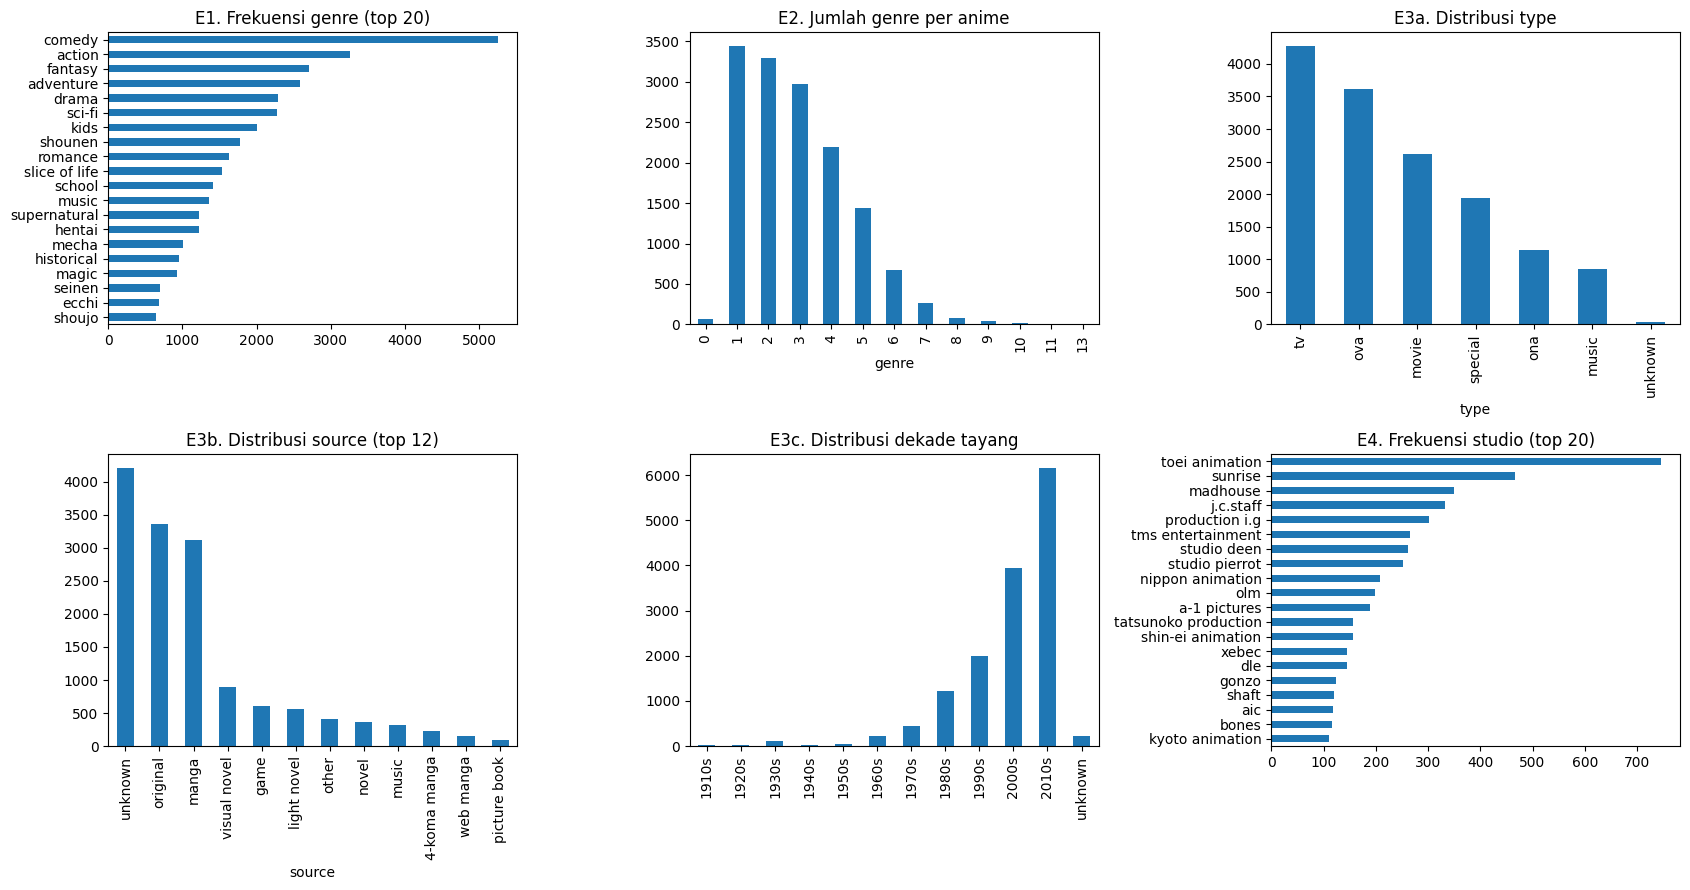

genre unik: 43 | rata-rata genre/anime: 2.9 | median: 3.0
studio unik: 509 | studio dengan <=2 judul: 46.0%
decade unknown: 223 | source unknown: 4210 | genre kosong: 64


In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(17, 9))

# E1 genre
gc = pd.Series([g for gs in genre_sets for g in gs]).value_counts()
gc.head(20).iloc[::-1].plot.barh(ax=ax[0,0], title="E1. Frekuensi genre (top 20)")

# E2 jumlah genre per anime
genre_sets.map(len).value_counts().sort_index().plot.bar(ax=ax[0,1], title="E2. Jumlah genre per anime")

# E3 type / source / decade
type_s.value_counts().plot.bar(ax=ax[0,2], title="E3a. Distribusi type")
source_s.value_counts().head(12).plot.bar(ax=ax[1,0], title="E3b. Distribusi source (top 12)")
decade_s.value_counts().sort_index().plot.bar(ax=ax[1,1], title="E3c. Distribusi dekade tayang")

# E4 studio
studio_freq = pd.Series([s for ss in studio_sets for s in ss]).value_counts()
studio_freq.head(20).iloc[::-1].plot.barh(ax=ax[1,2], title="E4. Frekuensi studio (top 20)")
plt.tight_layout(); plt.savefig(OUT/"eda_catalog.png", dpi=130); plt.show()

print("genre unik:", len(gc), "| rata-rata genre/anime:", genre_sets.map(len).mean().round(2), "| median:", genre_sets.map(len).median())
print(f"studio unik: {len(studio_freq)} | studio dengan <=2 judul: {(studio_freq <= 2).mean():.1%}")
print("decade unknown:", int((decade_s == 'unknown').sum()), "| source unknown:", int((source_s == 'unknown').sum()), "| genre kosong:", int((genre_sets.map(len) == 0).sum()))

### 5.3 EDA popularitas dan hubungan type × source (E5, E7)

10% anime teratas menyumbang 77.7% total members (indikasi popularity bias)


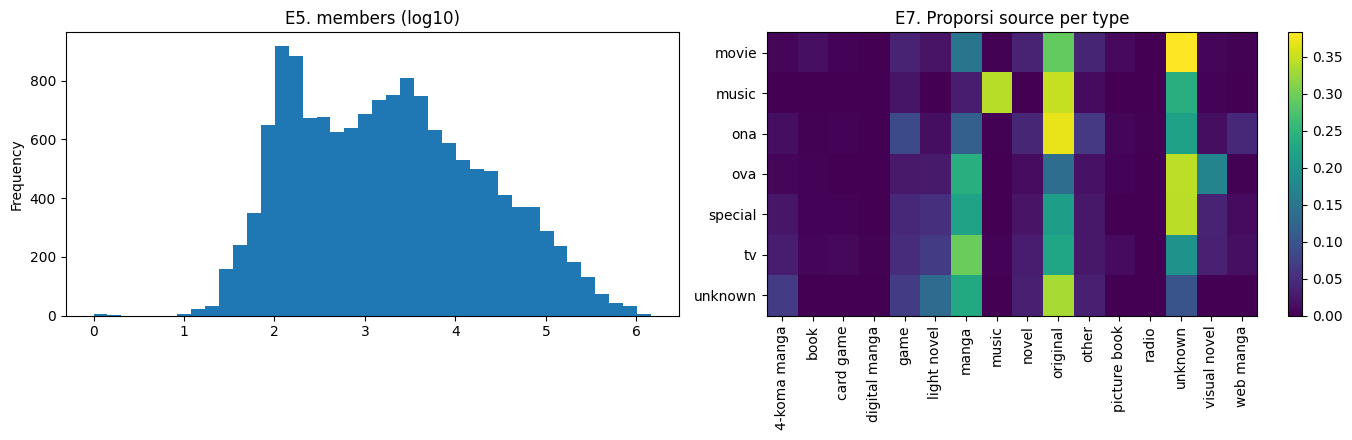

proporsi maksimum source dalam satu type: 0.38


In [ ]:
# E5 popularity (members, skala log) + E7 type x source
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
np.log10(anime_raw.members.clip(lower=1)).plot.hist(bins=40, ax=ax[0], title="E5. members (log10)")
top10_share = anime_raw.members.nlargest(int(0.1*N_RAW)).sum()/anime_raw.members.sum()
print(f"10% anime teratas menyumbang {top10_share:.1%} total members (indikasi popularity bias)")

ct = pd.crosstab(type_s, source_s, normalize="index")
im = ax[1].imshow(ct.values, aspect="auto"); ax[1].set_xticks(range(ct.shape[1])); ax[1].set_xticklabels(ct.columns, rotation=90)
ax[1].set_yticks(range(ct.shape[0])); ax[1].set_yticklabels(ct.index); ax[1].set_title("E7. Proporsi source per type"); plt.colorbar(im, ax=ax[1])
plt.tight_layout(); plt.savefig(OUT/"eda_popularity_corr.png", dpi=130); plt.show()
print("proporsi maksimum source dalam satu type:", round(float(ct.values.max()), 2))

### 5.4 EDA pengguna (E6) — membaca UserAnimeList per-chunk dengan sampling pengguna

baca data: 65s | baris disukai: 1,657,744 | pengguna: 13,431


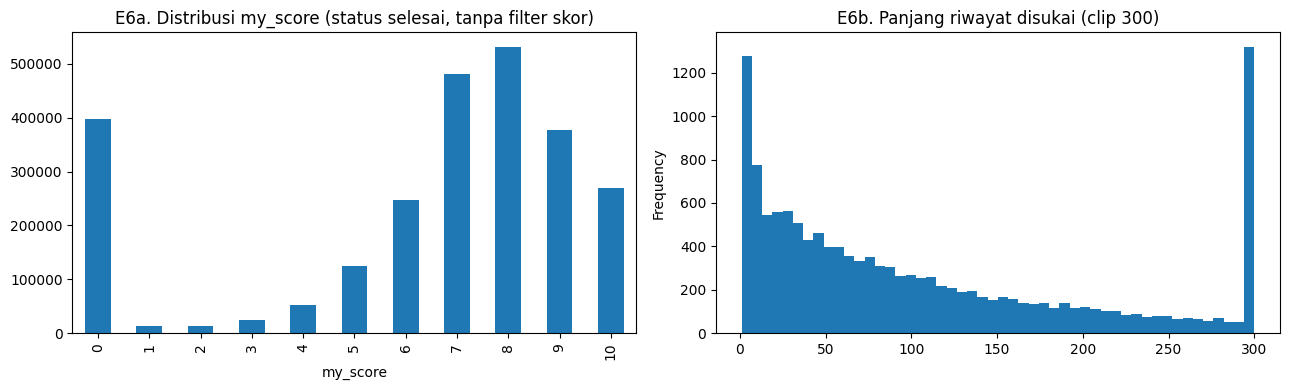

status_counts:
 my_status
1     201702.0
2    2528301.0
3     150942.0
4     158606.0
6     985729.0
count    13431.0
mean       123.4
std        155.4
min          1.0
25%         27.0
50%         75.0
75%        163.0
max       2487.0


In [ ]:
valid_ids = set(anime_raw.anime_id)
usecols = ["username","anime_id","my_score","my_status","my_last_updated"]
parts, score_counts, status_counts = [], pd.Series(dtype=float), pd.Series(dtype=float)
t0 = time.time()

for ch in pd.read_csv(USERANIME_CSV, usecols=usecols, chunksize=2_000_000):
    h = pd.util.hash_pandas_object(ch["username"].astype(str), index=False) % 100
    ch = ch[h < USER_SAMPLE_PCT]
    status_counts = status_counts.add(ch.my_status.value_counts(), fill_value=0)
    comp = ch[ch.my_status == 2]
    score_counts = score_counts.add(comp.my_score.value_counts(), fill_value=0)
    ch = comp[(comp.my_score >= REL_SCORE) & comp.anime_id.isin(valid_ids)]
    parts.append(ch)

ua_raw = pd.concat(parts, ignore_index=True).drop_duplicates(["username","anime_id"])
print(f"baca data: {time.time()-t0:.0f}s | baris disukai: {len(ua_raw):,} | pengguna: {ua_raw.username.nunique():,}")

hist_len = ua_raw.groupby("username").size()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
score_counts.sort_index().plot.bar(ax=ax[0], title="E6a. Distribusi my_score (status selesai, tanpa filter skor)")
hist_len.clip(upper=300).plot.hist(bins=50, ax=ax[1], title="E6b. Panjang riwayat disukai (clip 300)")
plt.tight_layout(); plt.savefig(OUT/"eda_users.png", dpi=130); plt.show()

print("status_counts:\n", status_counts.to_string()); print(hist_len.describe().round(1).to_string())

## 6. Preprocessing Data

In [ ]:
anime = anime_raw.copy()

anime["genre_set"] = anime["genre"].map(split_multi)
anime["studio_set"] = anime["studio"].map(split_multi)
anime["type_c"] = (
    anime["type"].fillna("unknown")
    .astype(str).str.strip().str.lower()
)
anime["source_c"] = (
    anime["source"].fillna("unknown")
    .astype(str).str.strip().str.lower()
)
anime["year"] = anime.apply(extract_year, axis=1)
anime["decade"] = anime["year"].map(
    lambda y: f"{int(y//10*10)}s" if pd.notna(y) else "unknown"
)

active = (
    anime.genre_set.map(len)
    + anime.studio_set.map(len)
    + (anime.type_c != "unknown")
    + (anime.source_c != "unknown")
    + (anime.decade != "unknown")
)

n_before = len(anime)
anime = anime[active > 0].reset_index(drop=True)

print(
    f"katalog: {n_before} -> {len(anime)} "
    f"(dibuang {n_before-len(anime)} tanpa atribut)"
)

N = len(anime)

id2idx = {
    a: i for i, a in enumerate(anime.anime_id.values)
}

print(
    "genre unik:",
    len({g for gs in anime.genre_set for g in gs}),
    "| studio unik:",
    len({s for ss in anime.studio_set for s in ss}),
    "| decade:",
    sorted(anime.decade.unique())
)

katalog: 14478 -> 14478 (dibuang 0 tanpa atribut)
genre unik: 43 | studio unik: 509 | decade: ['1910s', '1920s', '1930s', '1940s', '1950s', '1960s', '1970s', '1980s', '1990s', '2000s', '2010s', 'unknown']


## 7. Feature engineering: multi-hot per kelompok + pembobotan
Fitur berupa vektor biner (multi-hot), sehingga StandardScaler tidak dipakai: karena akan memperbesar pengaruh fitur langka (genre/studio yang jarang) dan merusak makna himpunan pada Jaccard. Skala antar fitur dikendalikan lewat pembobotan antar kelompok fitur dan normalisasi per kelompok untuk FCM

In [ ]:
def multi_hot(sets):
    vocab = sorted({x for s in sets for x in s}); v2i = {v:i for i,v in enumerate(vocab)}
    rows, cols = [], []
    for r, s in enumerate(sets):
        for x in s: rows.append(r); cols.append(v2i[x])
    M = sp.csr_matrix((np.ones(len(rows), np.float32), (rows, cols)), shape=(len(sets), len(vocab)))
    return M, vocab

def episode_bucket(e):
    if pd.isna(e): return []
    return ["short"] if e <= 13 else (["medium"] if e <= 30 else ["long"])

def build_groups(use_episode_group=False):
    g = {}
    g["genre"],  _ = multi_hot(anime.genre_set.tolist())
    g["studio"], _ = multi_hot(anime.studio_set.tolist())
    g["type"],   _ = multi_hot(anime.type_c.map(lambda x:[x]).tolist())
    g["source"], _ = multi_hot(anime.source_c.map(lambda x:[x]).tolist())
    g["decade"], _ = multi_hot(anime.decade.map(lambda x:[x]).tolist())
    if use_episode_group and "episodes" in anime:                       # FE5 (ablasi)
        g["episodes"], _ = multi_hot(anime.episodes.map(episode_bucket).tolist())
    return g

GROUPS = build_groups()
GN = list(GROUPS)
SIZES = {g: np.asarray(M.sum(1)).ravel().astype(np.float32) for g, M in GROUPS.items()}
print({g: M.shape[1] for g, M in GROUPS.items()})

def weight_vector(w_genre):
    """genre = w_genre, kelompok lain berbagi sisa secara merata (FE1); jumlah = 1."""
    rest = (1 - w_genre) / (len(GN) - 1)
    return np.array([w_genre if g == "genre" else rest for g in GN], np.float32)


def jaccard_stack(idx):
    """Jaccard per kelompok antara anime idx dan seluruh katalog. -> (G, len(idx), N), mask valid (union>0)"""
    idx = np.asarray(idx)
    out = np.zeros((len(GN), len(idx), N), np.float32); valid = np.zeros_like(out, dtype=bool)
    for gi, g in enumerate(GN):
        M = GROUPS[g]
        inter = (M[idx] @ M.T).toarray().astype(np.float32)
        union = SIZES[g][idx][:, None] + SIZES[g][None, :] - inter
        v = union > 0
        out[gi] = np.where(v, inter / np.maximum(union, 1e-9), 0); valid[gi] = v
    return out, valid

def combine(stack, valid, w):
    """sim = sum_g w_g J_g / sum_g w_g [valid]; kelompok kosong di kedua anime dikeluarkan & bobot dinormalisasi ulang."""
    w3 = w[:, None, None]
    return (w3 * stack).sum(0) / np.maximum((w3 * valid).sum(0), 1e-9)

# matriks gabungan untuk metrik diversity (model-agnostik, tanpa bobot)
ALL = sp.hstack(list(GROUPS.values())).tocsr(); ALL_SIZE = np.asarray(ALL.sum(1)).ravel()

{'genre': 43, 'studio': 509, 'type': 7, 'source': 16, 'decade': 12}


## 8. Riwayat pengguna, split temporal, dan split pengguna

In [ ]:
# riwayat disukai (selesai, skor >= REL_SCORE) dari Bagian 5.4, hanya untuk anime yang lolos preprocessing
ua = ua_raw[ua_raw.anime_id.isin(id2idx)].copy()
ua["t"] = pd.to_datetime(ua["my_last_updated"], errors="coerce")
ua = ua.dropna(subset=["t"]).sort_values(["username","t"])
print(f"baris disukai: {len(ua):,} | pengguna: {ua.username.nunique():,}")

baris disukai: 1,657,744 | pengguna: 13,431


In [ ]:
users = []
for uname, g in ua.groupby("username", sort=False):
    idxs = g.anime_id.map(id2idx).values.astype(int)
    if len(idxs) < MIN_HIST: continue
    n_hist = int(TRAIN_FRAC * len(idxs))
    users.append(dict(username=uname, hist=idxs[:n_hist], rel=set(idxs[n_hist:].tolist())))
print("pengguna layak:", len(users))
perm = rng_global.permutation(len(users))
n_val = int(VAL_FRAC * len(users))
VAL_USERS  = [users[i] for i in perm[:n_val]][:N_VAL_MAX]
TEST_USERS = [users[i] for i in perm[n_val:]][:N_TEST_MAX]
assert not ({u["username"] for u in VAL_USERS} & {u["username"] for u in TEST_USERS})
print(f"validation: {len(VAL_USERS)} | test: {len(TEST_USERS)} | rata-rata |hist|={np.mean([len(u['hist']) for u in users]):.1f}, |rel|={np.mean([len(u['rel']) for u in users]):.1f}")
json.dump({"n_users_eligible": len(users), "n_val": len(VAL_USERS), "n_test": len(TEST_USERS),
           "user_sample_pct": USER_SAMPLE_PCT, "seed": SEED}, open(OUT/"split_info.json","w"), indent=2)

pengguna layak: 11203
validation: 300 | test: 1000 | rata-rata |hist|=117.0, |rel|=29.8


## 9. Metrik evaluasi

In [ ]:
LOG2 = np.log2(np.arange(2, TOPN + 2))
POP = anime["members"].fillna(0).values.astype(float) if "members" in anime else np.ones(N)
POP_P = POP / POP.sum()

def user_metrics(recs, rel):
    recs = np.asarray(recs); hits = np.array([r in rel for r in recs], float)
    nh = hits.sum(); dcg = (hits / LOG2[:len(recs)]).sum()
    idcg = (1 / LOG2[:min(len(rel), TOPN)]).sum()
    # intra-list diversity
    R = ALL[recs]; inter = (R @ R.T).toarray(); sz = ALL_SIZE[recs]
    union = sz[:, None] + sz[None, :] - inter
    jac = np.where(union > 0, inter / np.maximum(union, 1e-9), 0)
    iu = np.triu_indices(len(recs), 1)
    return dict(ndcg=dcg / idcg if idcg > 0 else 0.0, hit=float(nh > 0), prec=nh / TOPN, rec=nh / len(rel),
                ild=float(1 - jac[iu].mean()), novelty=float(-np.log2(np.clip(POP_P[recs], 1e-12, None)).mean()))

def evaluate(users, rec_fn, L=L_INPUT):
    rows, all_recs = [], set()
    for k, u in enumerate(users):
        recs = rec_fn(u["hist"], L, k)
        rows.append(user_metrics(recs, u["rel"])); all_recs.update(map(int, recs))
    df = pd.DataFrame(rows); df.attrs["coverage"] = len(all_recs) / N
    return df

def top_n(scores, hist):
    s = scores.astype(np.float64).copy(); s[hist] = -np.inf
    top = np.argpartition(-s, TOPN)[:TOPN]
    return top[np.argsort(-s[top], kind="stable")]

def recency_weights(L, lam):
    return lam ** np.arange(L - 1, -1, -1)

## 10. Baseline dan model

In [ ]:
# B0 acak, B1 terpopuler
def rec_random(hist, L, k):
    r = np.random.default_rng(SEED + k); cand = np.setdiff1d(np.arange(N), hist)
    return r.choice(cand, TOPN, replace=False)
POP_ORDER = np.argsort(-POP, kind="stable")
def rec_popular(hist, L, k):
    h = set(map(int, hist)); return np.array([i for i in POP_ORDER if i not in h][:TOPN])

# M1: KNN berbobot fitur + Jaccard, skor per-item dgn recency
def make_knn(w, K, lam):
    def fn(hist, L, k):
        inp = hist[-L:]; st, va = jaccard_stack(inp); sim = combine(st, va, w)
        sim[np.arange(len(inp)), inp] = -np.inf
        nb = np.argpartition(-sim, K, axis=1)[:, :K]; vals = np.take_along_axis(sim, nb, 1)
        wv = recency_weights(len(inp), lam); scores = np.zeros(N)
        np.add.at(scores, nb.ravel(), (vals * wv[:, None]).ravel())
        return top_n(scores, hist)
    return fn

# M2: FCM (implementasi sendiri) + cosine atas vektor keanggotaan
def fcm(X, c, m=2.0, max_iter=300, tol=1e-5, seed=SEED):
    n = X.shape[0]
    x2 = (X ** 2).sum(1)[:, None]

    Cn = KMeans(
        n_clusters=c,
        n_init=1,
        random_state=seed
    ).fit(X).cluster_centers_.astype(np.float32)

    U = np.zeros((n, c))

    for it in range(max_iter):
        d2 = np.maximum(
            x2 - 2 * X @ Cn.T + (Cn ** 2).sum(1)[None, :],
            1e-12
        )
        inv = d2 ** (-1.0 / (m - 1))
        Un = inv / inv.sum(1, keepdims=True)
        done = np.abs(Un - U).max() < tol
        U = Un

        if done:
            break

        Um = U ** m
        Cn = (Um.T @ X) / np.maximum(
            Um.sum(0)[:, None], 1e-12
        )

    J = float(((U ** m) * d2).sum())
    fpc = float((U ** 2).sum() / n)
    collapsed = fpc < 1.2 / c

    return U.astype(np.float32), J, fpc, it + 1, collapsed

def weighted_dense_X(w):
    """FE4: skala tiap kelompok sqrt(w_g / n_g), n_g = rata-rata jumlah atribut aktif."""
    blocks = []
    for gi, g in enumerate(GN):
        n_g = max(SIZES[g].mean(), 1e-9); blocks.append(GROUPS[g].toarray() * np.sqrt(w[gi] / n_g))
    return np.hstack(blocks).astype(np.float32)

def make_membership_rec(U, lam):
    Un = U / np.maximum(np.linalg.norm(U, axis=1, keepdims=True), 1e-9)
    def fn(hist, L, k):
        inp = hist[-L:]; sims = Un[inp] @ Un.T
        return top_n(recency_weights(len(inp), lam) @ sims, hist)
    return fn

## 11. Tuning pada VALIDATION
Semua hiperparameter dipilih hanya dari pengguna validation, test tidak disentuh di sini.

In [ ]:
# 11a. KNN-Jaccard: user di loop luar (hitung Jaccard sekali), konfigurasi di loop dalam
W_CONFIGS = {f"wg={wg}": weight_vector(wg) for wg in W_GENRE_GRID}

def tune_knn(users, L=L_INPUT):
    res = {}
    for u in users:
        inp = u["hist"][-L:]; st, va = jaccard_stack(inp); rel = u["rel"]
        idcg = (1 / LOG2[:min(len(rel), TOPN)]).sum()
        for wname, w in W_CONFIGS.items():
            sim = combine(st, va, w); sim[np.arange(len(inp)), inp] = -np.inf
            for K in K_GRID:
                nb = np.argpartition(-sim, K, axis=1)[:, :K]; vals = np.take_along_axis(sim, nb, 1)
                for lam in LAMBDA_GRID:
                    wv = recency_weights(len(inp), lam); scores = np.zeros(N)
                    np.add.at(scores, nb.ravel(), (vals * wv[:, None]).ravel())
                    recs = top_n(scores, u["hist"])
                    hits = np.array([r in rel for r in recs], float)
                    res.setdefault((wname, K, lam), []).append((hits / LOG2).sum() / idcg)
    return pd.DataFrame([dict(w=k[0], K=k[1], lam=k[2], ndcg_val=np.mean(v)) for k, v in res.items()])

t0 = time.time(); tune_knn_df = tune_knn(VAL_USERS); print(f"tuning KNN: {time.time()-t0:.0f}s")
tune_knn_df.sort_values("ndcg_val", ascending=False).to_csv(OUT/"tuning_knn.csv", index=False)
best_m1 = tune_knn_df.sort_values("ndcg_val", ascending=False).iloc[0]
print("best M1:", dict(best_m1))
tune_knn_df.sort_values("ndcg_val", ascending=False).head(10)

tuning KNN: 4s
best M1: {'w': 'wg=0.5', 'K': np.int64(20), 'lam': np.float64(1.0), 'ndcg_val': np.float64(0.07587949666593533)}


,w,K,lam,ndcg_val
15,wg=0.5,20,1.0,0.075879
3,wg=0.4,20,1.0,0.075728
14,wg=0.5,20,0.9,0.074536
27,wg=0.6,20,1.0,0.071628
26,wg=0.6,20,0.9,0.071299
13,wg=0.5,20,0.8,0.070336
2,wg=0.4,20,0.9,0.070109
16,wg=0.5,50,0.7,0.068209
1,wg=0.4,20,0.8,0.067864
5,wg=0.4,50,0.8,0.067861


In [75]:
# 11b. FCM: bobot kelompok = bobot terbaik M1 (selaras desain)
W_BEST = W_CONFIGS[best_m1.w]
X_W = weighted_dense_X(W_BEST)
def tune_membership(U_dict, users, L=L_INPUT):
    rows = []
    for key, U in U_dict.items():
        Un = U / np.maximum(np.linalg.norm(U, axis=1, keepdims=True), 1e-9)
        sc = {lam: [] for lam in LAMBDA_GRID}
        for u in users:
            inp = u["hist"][-L:]; sims = Un[inp] @ Un.T; rel = u["rel"]; idcg = (1/LOG2[:min(len(rel),TOPN)]).sum()
            for lam in LAMBDA_GRID:
                recs = top_n(recency_weights(len(inp), lam) @ sims, u["hist"])
                sc[lam].append(((np.array([r in rel for r in recs], float)) / LOG2).sum() / idcg)
        for lam in LAMBDA_GRID: rows.append(dict(model_key=key, lam=lam, ndcg_val=np.mean(sc[lam])))
    return pd.DataFrame(rows)

FCM_U, fcm_info = {}, []
for c in C_GRID:
    for m in M_GRID:
        t0 = time.time(); U, J, fpc, its, col = fcm(X_W, c, m)
        fcm_info.append(dict(c=c, m=m, J=J, fpc=fpc, fpc_uniform=1/c, iters=its, collapsed=col, sec=round(time.time()-t0,1)))
        if not col: FCM_U[(c, m)] = U                   # konfigurasi yang runtuh tidak ikut tuning
fcm_info = pd.DataFrame(fcm_info); fcm_info.to_csv(OUT/"fcm_validity.csv", index=False); display(fcm_info)
print(f"{fcm_info.collapsed.sum()} dari {len(fcm_info)} konfigurasi FCM runtuh (keanggotaan ~seragam) dan dikeluarkan dari tuning")
assert FCM_U, "Semua konfigurasi FCM runtuh: turunkan m atau kurangi dimensi fitur"

tune_fcm_df = tune_membership(FCM_U, VAL_USERS)
tune_fcm_df[["c","m"]] = pd.DataFrame(tune_fcm_df.model_key.tolist(), index=tune_fcm_df.index)
tune_fcm_df = tune_fcm_df.drop(columns="model_key").sort_values("ndcg_val", ascending=False)
tune_fcm_df.to_csv(OUT/"tuning_fcm.csv", index=False); best_m2 = tune_fcm_df.iloc[0]; print("best M2:", dict(best_m2))


,c,m,J,fpc,fpc_uniform,iters,collapsed,sec
0,10,1.05,9442.107422,0.825272,0.100000,300,False,7.4
1,10,1.10,9051.197266,0.595345,0.100000,300,False,10.1
2,10,1.20,7615.006836,0.198115,0.100000,131,False,9.9
3,10,1.50,3844.755859,0.100000,0.100000,17,True,1.3
4,10,2.00,1215.818604,0.100000,0.100000,11,True,0.9
5,15,1.05,8960.027344,0.831815,0.066667,125,False,4.7
6,15,1.10,8534.549805,0.595492,0.066667,300,False,11.7
7,15,1.20,6981.929688,0.172477,0.066667,75,False,4.2
8,15,1.50,3139.230225,0.066667,0.066667,18,True,1.7
9,15,2.00,810.545715,0.066667,0.066667,11,True,1.2


7 dari 25 konfigurasi FCM runtuh (keanggotaan ~seragam) dan dikeluarkan dari tuning
best M2: {'lam': np.float64(0.9), 'ndcg_val': np.float64(0.025210815520821103), 'c': np.float64(40.0), 'm': np.float64(1.1)}


## 11d. Validitas klaster (FCM)
c dan m dipilih berdasarkan NDCG@10 pada validation (tujuan sistem = kualitas rekomendasi). Indeks validitas internal di bawah ini dilaporkan sebagai pendukung, bukan kriteria pemilihan: *Xie-Beni* (khusus klaster lunak; makin kecil makin baik), *silhouette* (makin besar makin baik; disampel 3000 titik dari label argmax keanggotaan), *Davies-Bouldin* (makin kecil makin baik), dan *Calinski-Harabasz* (makin besar makin baik). Kurva *elbow* memakai fungsi tujuan J. Konfigurasi yang runtuh sudah dikeluarkan.

Waspadai runtuh sebagian: nilai Xie-Beni yang sangat besar (misal >> 10) atau n_klaster_terisi < c menandakan ada pusat klaster yang hampir sama, walaupun FPC tidak serendah 1/c. Konfigurasi seperti ini jangan dipilih meski NDCG-nya tinggi tanpa dicek manual.

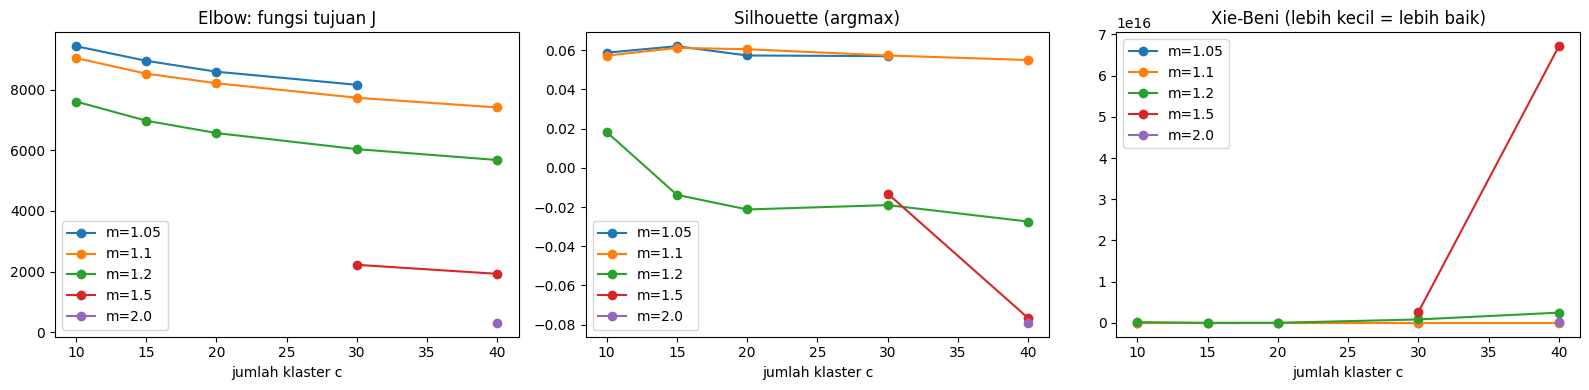

Konfigurasi terpilih (NDCG validation): {'lam': np.float64(0.9), 'ndcg_val': np.float64(0.025210815520821103), 'c': np.float64(40.0), 'm': np.float64(1.1)}


,c,m,J,fpc,fpc_uniform,iters,collapsed,sec,xie_beni,n_klaster_terisi,silhouette,davies_bouldin,calinski_harabasz
0,10,1.05,9442.1074,0.8253,0.1000,300,False,7.4,3.485100e+00,10.0,0.0588,3.2210,442.1877
1,10,1.10,9051.1973,0.5953,0.1000,300,False,10.1,4.364000e+00,10.0,0.0573,3.1136,450.2915
2,10,1.20,7615.0068,0.1981,0.1000,131,False,9.9,1.781171e+14,7.0,0.0183,5.2524,307.0063
3,10,1.50,3844.7559,0.1000,0.1000,17,True,1.3,NaN,NaN,NaN,NaN,NaN
4,10,2.00,1215.8186,0.1000,0.1000,11,True,0.9,NaN,NaN,NaN,NaN,NaN
5,15,1.05,8960.0273,0.8318,0.0667,125,False,4.7,2.985800e+00,15.0,0.0621,3.0124,354.8640
6,15,1.10,8534.5498,0.5955,0.0667,300,False,11.7,4.262300e+00,15.0,0.0612,3.0198,365.5248
7,15,1.20,6981.9297,0.1725,0.0667,75,False,4.2,1.241290e+12,11.0,-0.0138,3.3290,223.7898
8,15,1.50,3139.2302,0.0667,0.0667,18,True,1.7,NaN,NaN,NaN,NaN,NaN
9,15,2.00,810.5457,0.0667,0.0667,11,True,1.2,NaN,NaN,NaN,NaN,NaN


In [76]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

def xie_beni(X, U, m):
    Um = U.astype(np.float64) ** m
    Cn = (Um.T @ X) / np.maximum(Um.sum(0)[:, None], 1e-12)
    d2 = np.maximum((X ** 2).sum(1)[:, None] - 2 * X @ Cn.T + (Cn ** 2).sum(1)[None, :], 0)
    cd = ((Cn[:, None, :] - Cn[None, :, :]) ** 2).sum(-1); np.fill_diagonal(cd, np.inf)
    return float((Um * d2).sum() / (len(X) * cd.min()))

def hard_scores(X, lab):
    if len(np.unique(lab)) < 2:
        return dict(silhouette=np.nan, davies_bouldin=np.nan, calinski_harabasz=np.nan)
    return dict(silhouette=silhouette_score(X, lab, sample_size=min(3000, len(X)), random_state=SEED),
                davies_bouldin=davies_bouldin_score(X, lab), calinski_harabasz=calinski_harabasz_score(X, lab))

rows = []

for (c, m), U in FCM_U.items():
    lab = U.argmax(1)
    rows.append(dict(c=c, m=m, xie_beni=xie_beni(X_W, U, m), n_klaster_terisi=len(np.unique(lab)), **hard_scores(X_W, lab)))
fcm_val = fcm_info.merge(pd.DataFrame(rows), on=["c", "m"], how="left")
fcm_val.to_csv(OUT/"fcm_validity.csv", index=False)

ok = fcm_val[~fcm_val.collapsed]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for m, g in ok.groupby("m"):
    g = g.sort_values("c")
    ax[0].plot(g.c, g.J, marker="o", label=f"m={m}"); ax[1].plot(g.c, g.silhouette, marker="o", label=f"m={m}"); ax[2].plot(g.c, g.xie_beni, marker="o", label=f"m={m}")

ax[0].set_title("Elbow: fungsi tujuan J"); ax[1].set_title("Silhouette (argmax)"); ax[2].set_title("Xie-Beni (lebih kecil = lebih baik)")
for a in ax: a.set_xlabel("jumlah klaster c"); a.legend()
plt.tight_layout(); plt.savefig(OUT/"fcm_elbow.png", dpi=130); plt.show()
print("Konfigurasi terpilih (NDCG validation):", dict(best_m2))
display(fcm_val.round(4))

## 11e. Profil klaster FCM terpilih
Profil dihitung dari satuan asli: proporsi anime pada klaster yang memiliki tiap atribut (bukan nilai terskala). Anggota klaster ditentukan dari argmax keanggotaan; karena FCM bersifat lunak, anime dengan keanggotaan maksimum < 0,5 dihitung sebagai ambigu. Kolom nama_klaster diisi manual setelah membaca profil.

In [77]:
best_key = (int(best_m2.c), float(best_m2.m)); U = FCM_U[best_key]; lab = U.argmax(1)
voc = {"genre": sorted({x for s in anime.genre_set for x in s}), "studio": sorted({x for s in anime.studio_set for x in s}),
       "type": sorted(anime.type_c.unique()), "source": sorted(anime.source_c.unique()), "decade": sorted(anime.decade.unique())}

def top_attrs(g, idx, k):
    share = np.asarray(GROUPS[g][idx].mean(0)).ravel(); order = np.argsort(-share)[:k]
    return ", ".join(f"{voc[g][i]} ({share[i]:.0%})" for i in order)

prof = []
for k in [k for k in range(U.shape[1]) if (lab == k).any()]:
    idx = np.where(lab == k)[0]; ex = idx[np.argsort(-U[idx, k])[:5]]
    prof.append(dict(klaster=k, ukuran=len(idx), massa_keanggotaan=round(float(U[:, k].sum()), 1),
                     genre_dominan=top_attrs("genre", idx, 3), type=top_attrs("type", idx, 1), source=top_attrs("source", idx, 1),
                     dekade=top_attrs("decade", idx, 1), contoh_judul="; ".join(anime.title.values[ex]), nama_klaster=""))
prof = pd.DataFrame(prof); prof.to_csv(OUT/"fcm_cluster_profile.csv", index=False)

sizes = prof.ukuran
print(f"seed={SEED} | c={best_key[0]}, m={best_key[1]} | ukuran klaster min/median/maks = {sizes.min()}/{int(sizes.median())}/{sizes.max()}")
print(f"anime ambigu (keanggotaan maks < 0,5): {(U.max(1) < 0.5).mean():.1%} | rata-rata keanggotaan maks: {U.max(1).mean():.3f}")
pd.set_option("display.max_colwidth", 120); display(prof)

seed=42 | c=40, m=1.1 | ukuran klaster min/median/maks = 177/367/545
anime ambigu (keanggotaan maks < 0,5): 29.1% | rata-rata keanggotaan maks: 0.696


,klaster,ukuran,massa_keanggotaan,genre_dominan,type,source,dekade,contoh_judul,nama_klaster
0,0,381,432.4,"fantasy (27%), action (13%), music (13%)",ona (97%),original (41%),2010s (99%),Yaseruyagi; Hokori Inu no Hanashi; Origami of Landscape; Si Ling Bianma: Zhi Shijie Caozong Zhe Recap; Jirijiri Moyo...,
1,1,366,366.3,"kids (98%), fantasy (14%), adventure (10%)",movie (32%),original (71%),2010s (37%),Chounai Shinsengumi wo Tasuke-gumi Mezashi-tai no Koutsuu Anzen Rule wo Mamotte Mezase! Doubutsuen!; Manichi ga Tsur...,
2,2,545,541.5,"music (100%), kids (8%), drama (5%)",music (88%),original (32%),2010s (100%),Fake Style II; Hane; Ai Uta: Since 2007; One and Three Four; Himawari,
3,3,369,360.7,"comedy (97%), romance (34%), school (26%)",tv (65%),manga (91%),2000s (86%),Gokyoudai Monogatari; Noramimi 2; Shiawase Sou no Okojo-san; Yume wo Kanaeru Zou; Masuda Kousuke Gekijou Gag Manga B...,
4,4,249,266.5,"historical (84%), drama (76%), adventure (38%)",tv (63%),unknown (35%),1980s (26%),Souya Monogatari; Seton Doubutsuki: Kuma no Ko Jacky; Kazoku Robinson Hyouryuuki: Fushigi na Shima no Flone; Makiba ...,
5,5,337,329.9,"comedy (45%), romance (37%), drama (30%)",ova (92%),manga (92%),1990s (58%),Baby☆Love; Okama Hakusho; Kekkou Kamen; Nozomi Witches; Yuu☆Yuu☆Hakusho: Mu Mu Hakusho,
6,6,509,499.0,"comedy (72%), parody (13%), ecchi (12%)",special (97%),unknown (33%),2010s (99%),Ikeike! Momon-chan Specials; Nintama Rantarou: Ninjutsu Gakuen to Nazo no Onna - Kore wa Jiken Da yo! no Dan; Yuusha...,
7,7,366,325.7,"drama (94%), romance (88%), comedy (30%)",tv (67%),manga (47%),2000s (73%),Kimikiss Pure Rouge; Kita e.: Diamond Dust Drops; Myself; Yourself; Hanasakeru Seishounen; Kimi ga Nozomu Eien,
8,8,368,359.3,"action (87%), sci-fi (77%), mecha (28%)",tv (62%),original (53%),2010s (81%),Gundam Build Divers; Senki Zesshou Symphogear XV; Dragon Egg; Double Decker! Doug & Kirill; Infini-T Force,
9,9,316,337.0,"sci-fi (88%), action (81%), mecha (58%)",movie (47%),unknown (88%),1980s (47%),Syupeo Taegwon V; 84 Taekwon V; Roboteuwang Sseonsyakeu; Kkureogi Balmyeongwang; Hwanggeum Nalgae 1.2.3.,


## 12. Evaluasi akhir pada TEST

In [78]:
MODELS = {
  "B0 Acak":            (rec_random,  "-"),
  "B1 Terpopuler":      (rec_popular, "-"),
  "M1 KNN-Jaccard":     (make_knn(W_CONFIGS[best_m1.w], int(best_m1.K), float(best_m1.lam)),    f"{best_m1.w}, K={int(best_m1.K)}, lam={best_m1.lam}"),
  "M2 FCM+cosine":      (make_membership_rec(FCM_U[(int(best_m2.c), float(best_m2.m))], float(best_m2.lam)), f"c={int(best_m2.c)}, m={best_m2.m}, lam={best_m2.lam}"),
}

per_user, rows = {}, []

for name, (fn, cfg) in MODELS.items():
    t0 = time.time(); df = evaluate(TEST_USERS, fn); per_user[name] = df

    r = np.random.default_rng(SEED); bs = [df.ndcg.values[r.integers(0, len(df), len(df))].mean() for _ in range(1000)]
    rows.append({"Model": name, "Konfigurasi (dari validation)": cfg, "Validasi": "temporal + user split",
                 "NDCG@10": df.ndcg.mean(), "NDCG CI95": f"[{np.percentile(bs,2.5):.4f}, {np.percentile(bs,97.5):.4f}]",
                 "HitRate@10": df.hit.mean(), "Prec@10": df.prec.mean(), "Rec@10": df.rec.mean(),
                 "Diversity": df.ild.mean(), "Novelty": df.novelty.mean(), "Coverage": df.attrs["coverage"]})

    print(f"{name}: {time.time()-t0:.0f}s")

RESULTS = pd.DataFrame(rows); RESULTS.to_csv(OUT/"results_table.csv", index=False)
pd.concat({k: v for k, v in per_user.items()}).to_csv(OUT/"results_per_user.csv")
RESULTS.round(4)

B0 Acak: 3s
B1 Terpopuler: 2s
M1 KNN-Jaccard: 6s
M2 FCM+cosine: 1s


,Model,Konfigurasi (dari validation),Validasi,NDCG@10,NDCG CI95,HitRate@10,Prec@10,Rec@10,Diversity,Novelty,Coverage
0,B0 Acak,-,temporal + user split,0.0023,"[0.0012, 0.0035]",0.020,0.0020,0.0006,0.8983,17.4328,0.5002
1,B1 Terpopuler,-,temporal + user split,0.1214,"[0.1121, 0.1303]",0.560,0.1051,0.0489,0.7493,8.3556,0.0034
2,M1 KNN-Jaccard,"wg=0.5, K=20, lam=1.0",temporal + user split,0.0774,"[0.0699, 0.0847]",0.407,0.0661,0.0340,0.5692,13.1995,0.2114
3,M2 FCM+cosine,"c=40, m=1.1, lam=0.9",temporal + user split,0.0219,"[0.0184, 0.0257]",0.168,0.0206,0.0081,0.6531,13.7389,0.1969


In [79]:
# uji berpasangan (Wilcoxon) pada NDCG@10 per pengguna
def wtest(a, b):
    d = per_user[a].ndcg.values - per_user[b].ndcg.values
    return np.nan if np.allclose(d, 0) else wilcoxon(per_user[a].ndcg.values, per_user[b].ndcg.values).pvalue

pairs = [("M1 KNN-Jaccard","B1 Terpopuler"), ("M2 FCM+cosine","B1 Terpopuler"), ("M1 KNN-Jaccard","M2 FCM+cosine")]
sig = pd.DataFrame([dict(A=a, B=b, mean_diff_ndcg=per_user[a].ndcg.mean()-per_user[b].ndcg.mean(), p_wilcoxon=wtest(a,b)) for a,b in pairs])
sig.to_csv(OUT/"significance.csv", index=False); sig

,A,B,mean_diff_ndcg,p_wilcoxon
0,M1 KNN-Jaccard,B1 Terpopuler,-0.044029,2.293931e-14
1,M2 FCM+cosine,B1 Terpopuler,-0.099467,2.771704e-70
2,M1 KNN-Jaccard,M2 FCM+cosine,0.055439,1.057653e-40


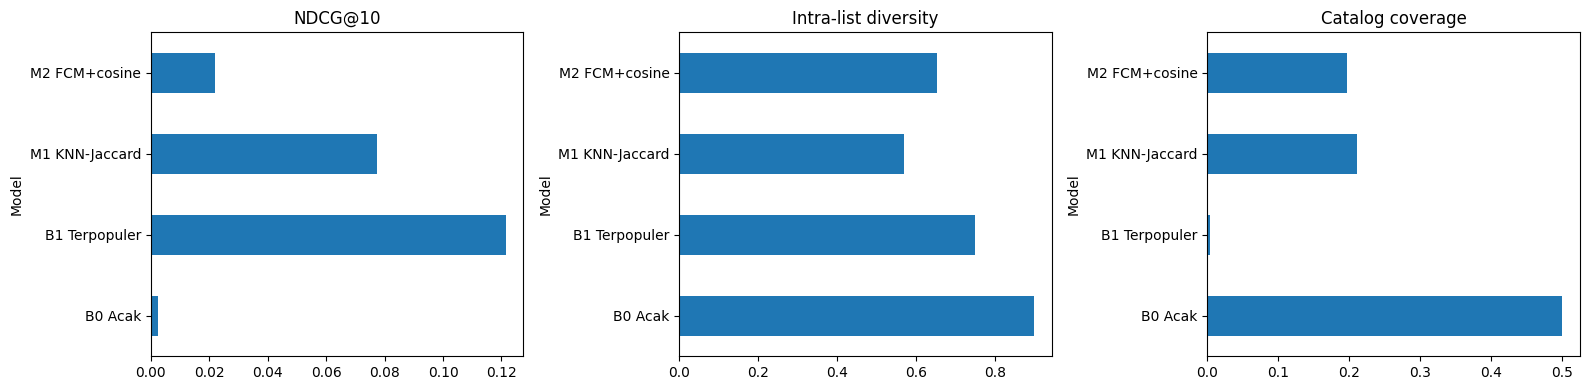

In [80]:
# grafik ringkas akurasi vs keberagaman vs coverage
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, col, t in zip(ax, ["NDCG@10", "Diversity", "Coverage"], ["NDCG@10", "Intra-list diversity", "Catalog coverage"]):
    RESULTS.set_index("Model")[col].plot.barh(ax=a, title=t)

plt.tight_layout(); plt.savefig(OUT/"results_overview.png", dpi=130); plt.show()

## 13. Analisis sensitivitas panjang input L (pada VALIDATION)

In [81]:
rows = []
for L in L_SENS:
    for name in ["B1 Terpopuler", "M1 KNN-Jaccard", "M2 FCM+cosine"]:
        df = evaluate(VAL_USERS, MODELS[name][0], L=L); rows.append(dict(L=L, model=name, ndcg=df.ndcg.mean(), hit=df.hit.mean(), div=df.ild.mean()))
sens = pd.DataFrame(rows); sens.to_csv(OUT/"sensitivity_L.csv", index=False)
sens.pivot(index="L", columns="model", values="ndcg").round(4)

model,B1 Terpopuler,M1 KNN-Jaccard,M2 FCM+cosine
L,,,
3,0.1361,0.0751,0.0207
5,0.1361,0.0759,0.0252
10,0.1361,0.0771,0.0237


## 14. Contoh kualitatif + penjelasan rekomendasi (KNN)

In [82]:
def explain_knn(u, w, K, lam, L=L_INPUT):
    inp = u["hist"][-L:]; st, va = jaccard_stack(inp); sim = combine(st, va, w); sim[np.arange(len(inp)), inp] = -np.inf
    recs = MODELS["M1 KNN-Jaccard"][0](u["hist"], L, 0); wv = recency_weights(len(inp), lam)
    src = [(inp[int(np.argmax(wv * np.clip(sim[:, j], 0, None)))]) for j in recs]
    return inp, recs, src

T = anime.title.values

for u in TEST_USERS[:3]:
    inp, recs, src = explain_knn(u, W_CONFIGS[best_m1.w], int(best_m1.K), float(best_m1.lam))
    print("INPUT :", [T[i] for i in inp])
    for j, s in zip(recs, src): print(f"   -> {T[j]:45s} (dari: {T[s]})  {'[HIT]' if j in u['rel'] else ''}")
    print()

INPUT : ['Break Blade 2: Ketsubetsu no Michi', 'Break Blade 3: Kyoujin no Ato', 'Fumiko no Kokuhaku', 'Canaan', 'Mahou Shoujo Madoka★Magica']
   -> Break Blade 4: Sanka no Chi                   (dari: Break Blade 2: Ketsubetsu no Michi)  [HIT]
   -> Break Blade 6: Doukoku no Toride              (dari: Break Blade 2: Ketsubetsu no Michi)  
   -> Break Blade 5: Shisen no Hate                 (dari: Break Blade 2: Ketsubetsu no Michi)  
   -> Break Blade                                   (dari: Break Blade 2: Ketsubetsu no Michi)  
   -> Fullmetal Alchemist: The Sacred Star of Milos (dari: Break Blade 2: Ketsubetsu no Michi)  
   -> One Piece 3D: Gekisou! Trap Coaster           (dari: Break Blade 2: Ketsubetsu no Michi)  
   -> Shingeki no Kyojin Movie 2: Jiyuu no Tsubasa  (dari: Break Blade 2: Ketsubetsu no Michi)  
   -> Ao no Exorcist Movie                          (dari: Break Blade 2: Ketsubetsu no Michi)  
   -> Cyborg 009: Call of Justice 1                 (dari: Break Blade 2: Ket

## Hasil


===== results_table.csv (4 baris) =====


,Model,Konfigurasi (dari validation),Validasi,NDCG@10,NDCG CI95,HitRate@10,Prec@10,Rec@10,Diversity,Novelty,Coverage
0,B0 Acak,-,temporal + user split,0.002324,"[0.0012, 0.0035]",0.020,0.0020,0.000574,0.898252,17.432849,0.500207
1,B1 Terpopuler,-,temporal + user split,0.121403,"[0.1121, 0.1303]",0.560,0.1051,0.048915,0.749334,8.355579,0.003384
2,M1 KNN-Jaccard,"wg=0.5, K=20, lam=1.0",temporal + user split,0.077375,"[0.0699, 0.0847]",0.407,0.0661,0.033972,0.569250,13.199483,0.211355
3,M2 FCM+cosine,"c=40, m=1.1, lam=0.9",temporal + user split,0.021936,"[0.0184, 0.0257]",0.168,0.0206,0.008074,0.653146,13.738909,0.196919



===== significance.csv (3 baris) =====


,A,B,mean_diff_ndcg,p_wilcoxon
0,M1 KNN-Jaccard,B1 Terpopuler,-0.044029,2.293931e-14
1,M2 FCM+cosine,B1 Terpopuler,-0.099467,2.771704e-70
2,M1 KNN-Jaccard,M2 FCM+cosine,0.055439,1.057653e-40



===== sensitivity_L.csv (9 baris) =====


,L,model,ndcg,hit,div
0,3,B1 Terpopuler,0.136144,0.610000,0.747514
1,3,M1 KNN-Jaccard,0.075116,0.376667,0.547419
2,3,M2 FCM+cosine,0.020689,0.160000,0.619111
3,5,B1 Terpopuler,0.136144,0.610000,0.747514
4,5,M1 KNN-Jaccard,0.075879,0.390000,0.556113
5,5,M2 FCM+cosine,0.025211,0.173333,0.643925
6,10,B1 Terpopuler,0.136144,0.610000,0.747514
7,10,M1 KNN-Jaccard,0.077107,0.370000,0.557133
8,10,M2 FCM+cosine,0.023686,0.166667,0.669398


... (4 outputs left out)


===== fcm_validity.csv (25 baris) =====


,c,m,J,fpc,fpc_uniform,iters,collapsed,sec,xie_beni,n_klaster_terisi,silhouette,davies_bouldin,calinski_harabasz
0,10,1.05,9442.107422,0.825272,0.100000,300,False,7.4,3.485104e+00,10.0,0.058761,3.220954,442.187714
1,10,1.10,9051.197266,0.595345,0.100000,300,False,10.1,4.363957e+00,10.0,0.057251,3.113573,450.291473
2,10,1.20,7615.006836,0.198115,0.100000,131,False,9.9,1.781171e+14,7.0,0.018296,5.252438,307.006256
3,10,1.50,3844.755859,0.100000,0.100000,17,True,1.3,NaN,NaN,NaN,NaN,NaN
4,10,2.00,1215.818604,0.100000,0.100000,11,True,0.9,NaN,NaN,NaN,NaN,NaN
5,15,1.05,8960.027344,0.831815,0.066667,125,False,4.7,2.985826e+00,15.0,0.062084,3.012353,354.864014
6,15,1.10,8534.549805,0.595492,0.066667,300,False,11.7,4.262312e+00,15.0,0.061205,3.019821,365.524841
7,15,1.20,6981.929688,0.172477,0.066667,75,False,4.2,1.241290e+12,11.0,-0.013765,3.329003,223.789764
8,15,1.50,3139.230225,0.066667,0.066667,18,True,1.7,NaN,NaN,NaN,NaN,NaN
9,15,2.00,810.545715,0.066667,0.066667,11,True,1.2,NaN,NaN,NaN,NaN,NaN



===== fcm_cluster_profile.csv (40 klaster) =====


,klaster,ukuran,massa_keanggotaan,genre_dominan,type,source,dekade
0,0,381,432.4,"fantasy (27%), action (13%), music (13%)",ona (97%),original (41%),2010s (99%)
1,1,366,366.3,"kids (98%), fantasy (14%), adventure (10%)",movie (32%),original (71%),2010s (37%)
2,2,545,541.5,"music (100%), kids (8%), drama (5%)",music (88%),original (32%),2010s (100%)
3,3,369,360.7,"comedy (97%), romance (34%), school (26%)",tv (65%),manga (91%),2000s (86%)
4,4,249,266.5,"historical (84%), drama (76%), adventure (38%)",tv (63%),unknown (35%),1980s (26%)
5,5,337,329.9,"comedy (45%), romance (37%), drama (30%)",ova (92%),manga (92%),1990s (58%)
6,6,509,499.0,"comedy (72%), parody (13%), ecchi (12%)",special (97%),unknown (33%),2010s (99%)
7,7,366,325.7,"drama (94%), romance (88%), comedy (30%)",tv (67%),manga (47%),2000s (73%)
8,8,368,359.3,"action (87%), sci-fi (77%), mecha (28%)",tv (62%),original (53%),2010s (81%)
9,9,316,337.0,"sci-fi (88%), action (81%), mecha (58%)",movie (47%),unknown (88%),1980s (47%)


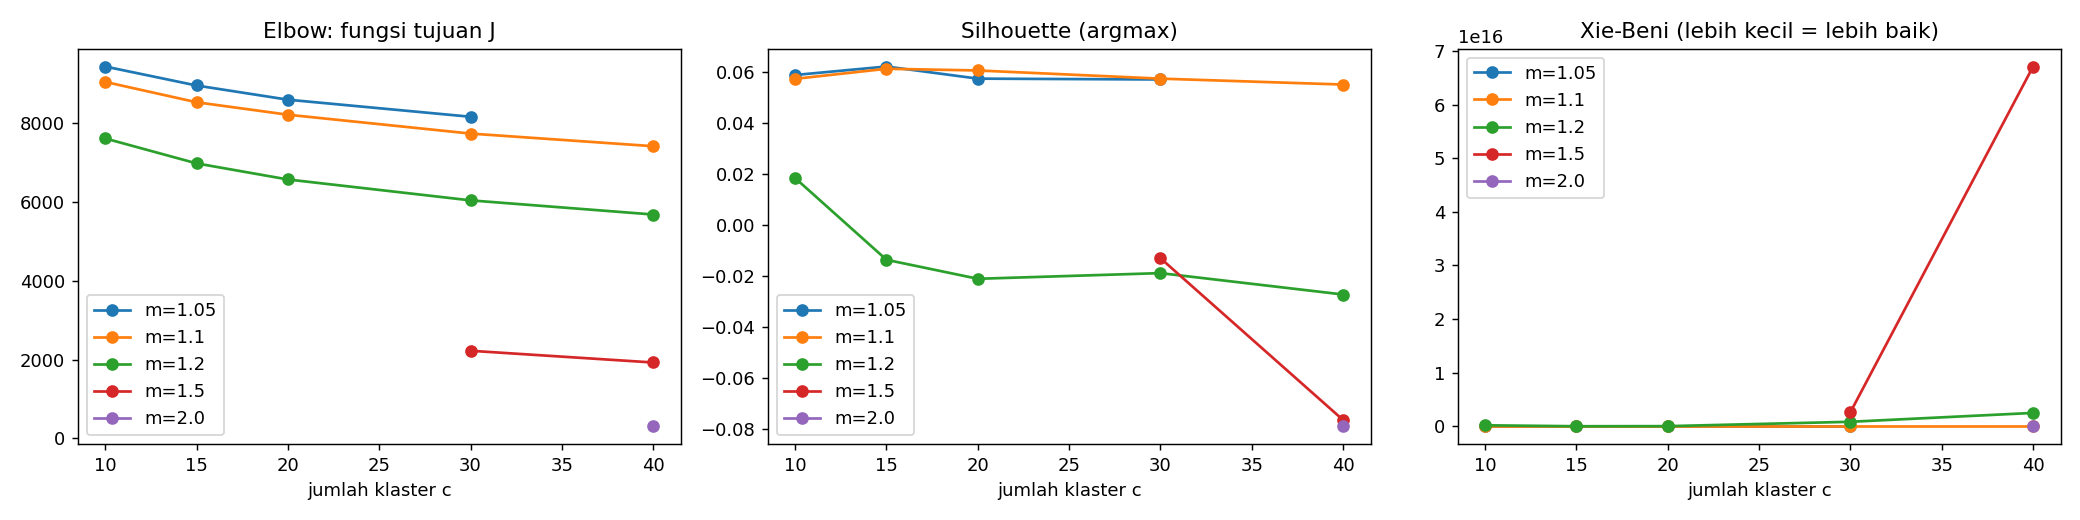

In [83]:
import pandas as pd
from pathlib import Path
from IPython.display import display, Image

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 80)

R = Path("results")

def show(name, n=None):
    df = pd.read_csv(R / name)
    print(f"\n===== {name} ({len(df)} baris) =====")
    display(df if n is None else df.head(n))

show("results_table.csv")
show("significance.csv")
show("sensitivity_L.csv")
show("tuning_knn.csv", 10)
show("tuning_fcm.csv", 10)
show("fcm_validity.csv")

prof = pd.read_csv(R / "fcm_cluster_profile.csv")
print(f"\n===== fcm_cluster_profile.csv ({len(prof)} klaster) =====")
display(prof.drop(columns=["contoh_judul", "nama_klaster"]))

display(Image(R / "fcm_elbow.png"))